<a href="https://colab.research.google.com/github/AsadLearns/deeplearning-training-/blob/main/pba2deeplearningadt23socb1586.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import os, sys

print("TensorFlow Version:", tf.__version__)
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"✅ GPU Detected: {gpu_devices}")
    !nvidia-smi
else:
    print("✅ Local High-Performance Runtime Connected Successfully!")

TensorFlow Version: 2.21.0
✅ Local High-Performance Runtime Connected Successfully!


In [ ]:
import pandas as pd
import numpy as np

# Column definitions for NASA C-MAPSS
index_cols = ["unit_id", "cycle"]
setting_cols = ["setting_1", "setting_2", "setting_3"]
sensor_cols = [f"s_{i}" for i in range(1, 22)]
all_cols = index_cols + setting_cols + sensor_cols

# Load training, testing, and ground-truth RUL files
train_df = pd.read_csv("data/raw/train_FD001.txt", sep=r"\s+", header=None, names=all_cols)
test_df = pd.read_csv("data/raw/test_FD001.txt", sep=r"\s+", header=None, names=all_cols)
rul_df = pd.read_csv("data/raw/RUL_FD001.txt", sep=r"\s+", header=None, names=["true_rul"])

# Compute RUL for training engines (run to complete failure)
max_train_cycles = train_df.groupby("unit_id")["cycle"].transform("max")
train_df["RUL"] = max_train_cycles - train_df["cycle"]

print(f"✅ Training Units: {train_df['unit_id'].nunique()} engines | Total Rows: {train_df.shape[0]}")
print(f"✅ Testing Units : {test_df['unit_id'].nunique()} engines | Total Rows: {test_df.shape[0]}")
train_df.head(5)

✅ Training Units: 100 engines | Total Rows: 20631
✅ Testing Units : 100 engines | Total Rows: 13096


,unit_id,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Feature Selection: Prune 10 zero/near-zero variance flat channels
drop_cols = ["setting_1", "setting_2", "setting_3", "s_1", "s_5", "s_6", "s_10", "s_16", "s_18", "s_19"]
features = [c for c in sensor_cols if c not in drop_cols]
print(f"Selected {len(features)} Active Dynamic Sensors: {features}")

# Engine-level split by unit_id to prevent window leakage
units = train_df["unit_id"].unique()
train_split = train_df[train_df["unit_id"].isin(units[:81])].copy()
val_split = train_df[train_df["unit_id"].isin(units[81:])].copy()

# Fit scaler strictly on nominal healthy data (RUL >= 100)
scaler = MinMaxScaler(feature_range=(0, 1))
healthy_train = train_split[train_split["RUL"] >= 100]
scaler.fit(healthy_train[features])

def create_sequences(df, seq_len=30):
    df_s = df.copy()
    df_s[features] = scaler.transform(df[features])
    seqs, metas = [], []
    for uid, grp in df_s.groupby("unit_id"):
        vals = grp[features].values
        cycs = grp["cycle"].values
        ruls = grp["RUL"].values if "RUL" in grp.columns else np.zeros(len(grp))
        if len(grp) >= seq_len:
            for i in range(len(grp) - seq_len + 1):
                seqs.append(vals[i:i+seq_len])
                metas.append({"unit_id": int(uid), "cycle": int(cycs[i+seq_len-1]), "RUL": float(ruls[i+seq_len-1])})
    return np.array(seqs, dtype=np.float32), pd.DataFrame(metas)

X_train_h, meta_train_h = create_sequences(healthy_train)
X_val_h, meta_val_h = create_sequences(val_split[val_split["RUL"] >= 100])
X_test_all, meta_test = create_sequences(test_df)

print(f"✅ X_train_h shape: {X_train_h.shape}")
print(f"✅ X_val_h shape  : {X_val_h.shape}")
print(f"✅ X_test_all shape: {X_test_all.shape}")

Selected 14 Active Dynamic Sensors: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
✅ X_train_h shape: (5930, 30, 14)
✅ X_val_h shape  : (1802, 30, 14)
✅ X_test_all shape: (10196, 30, 14)


In [ ]:
from tensorflow.keras import models, layers, optimizers

model = models.Sequential([
    layers.Input(shape=(30, len(features))),
    layers.LSTM(64, return_sequences=True, activation="tanh", name="encoder_lstm_1"),
    layers.Dropout(0.1),
    layers.LSTM(32, return_sequences=False, activation="tanh", name="encoder_lstm_2"),
    layers.Dense(16, activation="relu", name="latent_bottleneck"),
    layers.RepeatVector(30, name="decoder_repeat"),
    layers.LSTM(32, return_sequences=True, activation="tanh", name="decoder_lstm_1"),
    layers.Dropout(0.1),
    layers.LSTM(64, return_sequences=True, activation="tanh", name="decoder_lstm_2"),
    layers.TimeDistributed(layers.Dense(len(features), activation="linear"), name="reconstruction")
])

model.compile(optimizer=optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_lstm_1 (LSTM)           │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_lstm_2 (LSTM)           │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_bottleneck (Dense)       │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_repeat (RepeatVector)   │ (None, 30, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_lstm_1 (LSTM)           │ (None, 30, 32)         │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_lstm_2 (LSTM)           │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction                  │ (None, 30, 14)         │           910 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,182 (254.62 KB)

 Trainable params: 65,182 (254.62 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras import callbacks

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)

# You can train directly:
history = model.fit(
    X_train_h, X_train_h,
    epochs=50,
    batch_size=64,
    validation_data=(X_val_h, X_val_h),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 17s 79ms/step - loss: 0.0528 - mae: 0.1729 - val_loss: 0.0181 - val_mae: 0.1037
Epoch 2/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - loss: 0.0147 - mae: 0.0946 - val_loss: 0.0124 - val_mae: 0.0882
Epoch 3/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - loss: 0.0123 - mae: 0.0878 - val_loss: 0.0117 - val_mae: 0.0861
Epoch 4/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.0111 - mae: 0.0833 - val_loss: 0.0101 - val_mae: 0.0796
Epoch 5/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.0103 - mae: 0.0802 - val_loss: 0.0098 - val_mae: 0.0782
Epoch 6/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.0102 - mae: 0.0794 - val_loss: 0.0097 - val_mae: 0.0779
Epoch 7/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - loss: 0.0101 - mae: 0.0790 - val_loss: 0.0098 - val_mae: 0.0779
Epoch 8/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - loss: 0.0100 - mae: 0.0787 - val_loss: 0.0097 - val_mae: 0.0777
Epoch 9/50
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - loss: 0.00

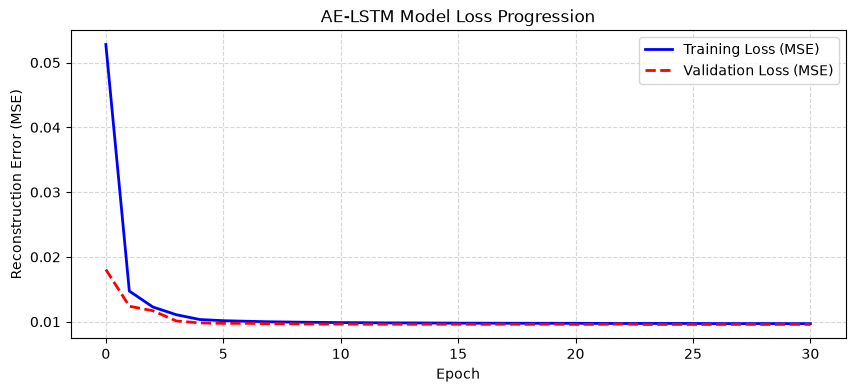

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss (MSE)", color="blue", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation Loss (MSE)", color="red", linestyle="--", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error (MSE)")
plt.title("AE-LSTM Model Loss Progression")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Validation-only threshold calibration
val_recons = model.predict(X_val_h)
val_mse = np.mean(np.square(X_val_h - val_recons), axis=(1, 2))
threshold = float(np.percentile(val_mse, 99.0))
print(f"🎯 Calibrated Anomaly Threshold (99th %ile Val): {threshold:.6f}")

# Inference on all test engine sequences
test_recons = model.predict(X_test_all)
test_mse = np.mean(np.square(X_test_all - test_recons), axis=(1, 2))

meta_test["anomaly_score"] = test_mse
meta_test["threshold"] = threshold
meta_test["is_anomaly"] = (test_mse > threshold).astype(int)

total_seqs = len(meta_test)
total_anoms = int(meta_test["is_anomaly"].sum())
print(f"Total Sequences Evaluated : {total_seqs}")
print(f"Flagged Anomalous Windows : {total_anoms} ({total_anoms/total_seqs*100:.2f}%)")
meta_test.head(10)

57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step
🎯 Calibrated Anomaly Threshold (99th %ile Val): 0.010897
319/319 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step
Total Sequences Evaluated : 10196
Flagged Anomalous Windows : 1495 (14.66%)


,unit_id,cycle,RUL,anomaly_score,threshold,is_anomaly
0,1,30,0.0,0.008664,0.010897,0
1,1,31,0.0,0.008612,0.010897,0
2,2,30,0.0,0.010351,0.010897,0
3,2,31,0.0,0.010299,0.010897,0
4,2,32,0.0,0.010596,0.010897,0
5,2,33,0.0,0.010324,0.010897,0
6,2,34,0.0,0.010238,0.010897,0
7,2,35,0.0,0.010437,0.010897,0
8,2,36,0.0,0.010201,0.010897,0
9,2,37,0.0,0.010251,0.010897,0


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Compute RUL for test set
max_test_cycles = test_df.groupby("unit_id")["cycle"].max().reset_index()
rul_df["unit_id"] = np.arange(1, len(rul_df) + 1)
max_test_cycles = max_test_cycles.merge(rul_df, on="unit_id")
cycle_map = dict(zip(max_test_cycles["unit_id"], max_test_cycles["cycle"] + max_test_cycles["true_rul"]))
meta_test["RUL"] = meta_test["unit_id"].map(cycle_map) - meta_test["cycle"]

# Benchmark: Severe degradation (RUL <= 30) vs Nominal Baseline (RUL >= 100)
bench_df = meta_test[(meta_test["RUL"] <= 30) | (meta_test["RUL"] >= 100)].copy()
y_true = (bench_df["RUL"] <= 30).astype(int)
y_pred = bench_df["is_anomaly"].values

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
recall = tp / (tp + fn)
specificity = tn / (tn + fp)
roc_auc = roc_auc_score(y_true, bench_df["anomaly_score"])

print("--- CLASSIFICATION / EVALUATION REPORT ---")
print(f"Sensitivity / Recall (RUL <= 30): {recall*100:.2f}% ({tp}/{tp+fn} degraded windows flagged)")
print(f"Specificity (RUL >= 100)        : {specificity*100:.2f}% ({tn}/{tn+fp} normal windows unflagged)")
print(f"ROC-AUC Score                   : {roc_auc:.4f}")
print("Confusion Matrix:\n", cm)

--- CLASSIFICATION / EVALUATION REPORT ---
Sensitivity / Recall (RUL <= 30): 98.19% (326/332 degraded windows flagged)
Specificity (RUL >= 100)        : 93.68% (6622/7069 normal windows unflagged)
ROC-AUC Score                   : 0.9950
Confusion Matrix:
 [[6622  447]
 [   6  326]]


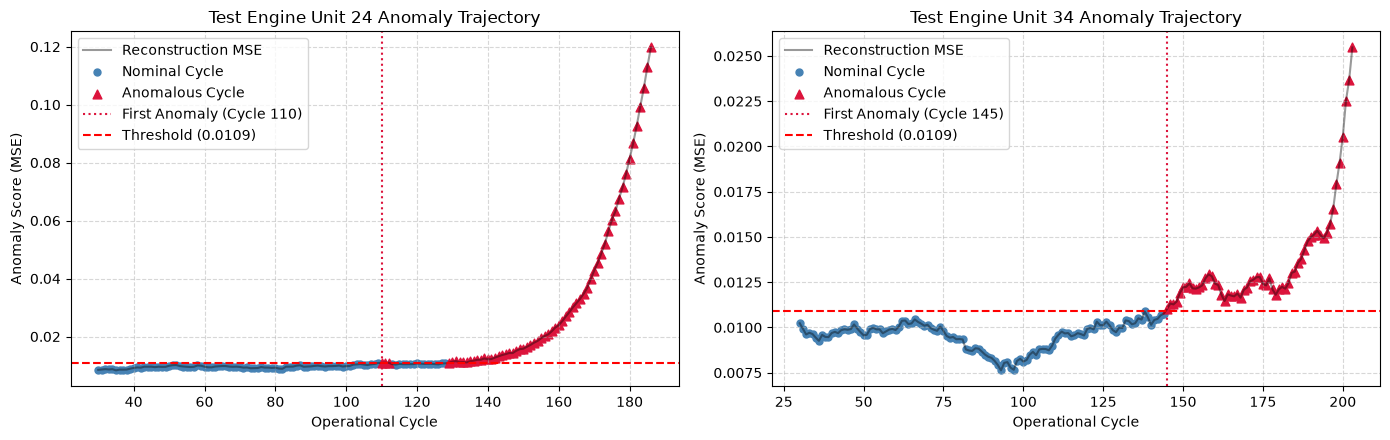

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for idx, uid in enumerate([24, 34]):
    ax = axes[idx]
    u_df = meta_test[meta_test["unit_id"] == uid].sort_values("cycle")
    nom = u_df[u_df["is_anomaly"] == 0]
    anom = u_df[u_df["is_anomaly"] == 1]

    ax.plot(u_df["cycle"], u_df["anomaly_score"], color="black", alpha=0.4, label="Reconstruction MSE")
    ax.scatter(nom["cycle"], nom["anomaly_score"], color="steelblue", s=25, label="Nominal Cycle")
    if not anom.empty:
        ax.scatter(anom["cycle"], anom["anomaly_score"], color="crimson", s=40, marker="^", label="Anomalous Cycle")
        ax.axvline(anom["cycle"].iloc[0], color="crimson", linestyle=":", label=f"First Anomaly (Cycle {anom['cycle'].iloc[0]})")
    ax.axhline(threshold, color="red", linestyle="--", label=f"Threshold ({threshold:.4f})")
    ax.set_title(f"Test Engine Unit {uid} Anomaly Trajectory")
    ax.set_xlabel("Operational Cycle")
    ax.set_ylabel("Anomaly Score (MSE)")
    ax.legend(loc="upper left")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Launch Streamlit in background
!streamlit run app.py &>/dev/null &
# Expose port 8501
!npx localtunnel --port 8501

OSError: Background processes not supported.